In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from uncertainties import ufloat
import uncertainties.unumpy as unp

# 1. Dynamische Pfadfindung zu 'common'
current_dir = Path.cwd()
if (current_dir / "common").exists():
    common_dir = (current_dir / "common").resolve()
elif (current_dir / "../common").exists():
    common_dir = (current_dir / "../common").resolve()
else:
    raise FileNotFoundError("Der Ordner 'common' konnte nicht gefunden werden.")

sys.path.insert(0, str(common_dir))

# Eigene Module importieren
import io_utils
import fitting
import fit_stats as stats
import plotting
import uncertainty as unc

print("Module erfolgreich geladen.")

#Messwerte wurden im Folgenden aus csv Dateien importiert

Module erfolgreich geladen.


Spezifischer Beta-Nulleffekt n_0^beta = (0.3600 ± 0.0346) 1/s
Plot gespeichert unter: figures\V253_Beta_Absorption_linear.pdf


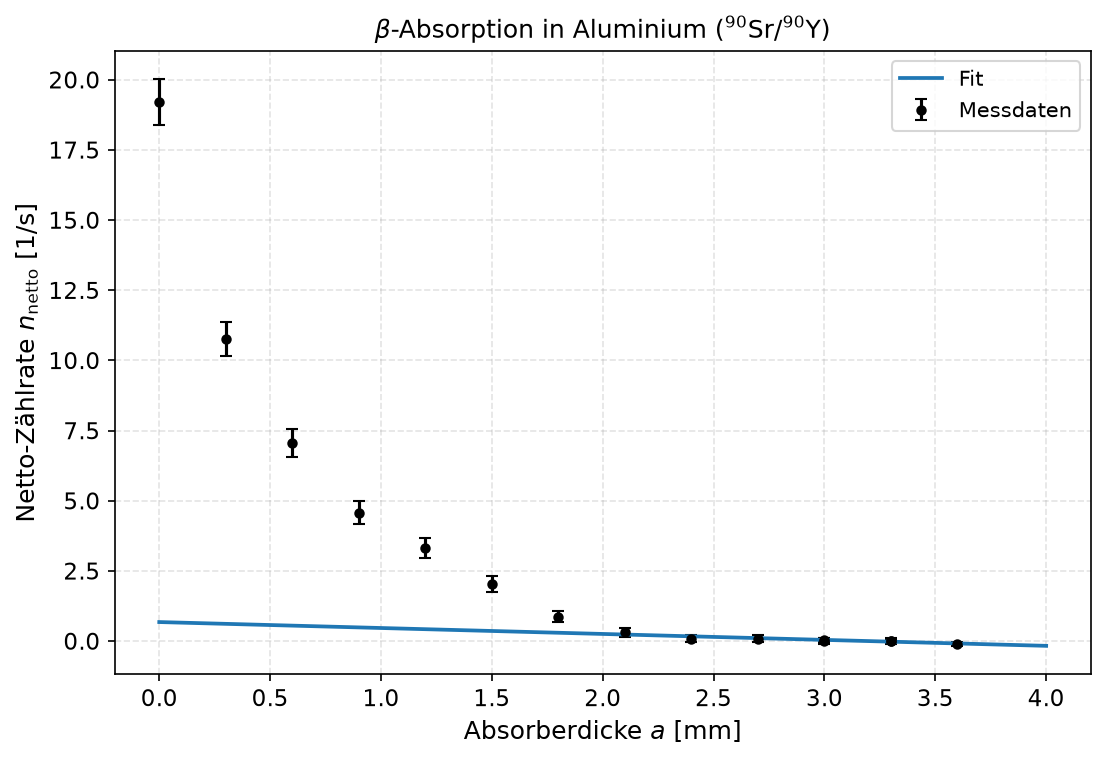

WindowsPath('figures/V253_Beta_Absorption_linear.pdf')

In [ ]:
# ==========================================
# 2. BETA-ABSORPTION IN ALUMINIUM (Sr-90)
# ==========================================

# Im Folgenden wird die im Messprotokoll stets als Zählrate bezeichnete Größe 
# als Zerfallsrate n, bzw n_0^\beta verwendet; 
# diese ist nicht mit den im Messprotokoll als Klicks beschriebenen Größe n 
# zu verwechseln. Wir berechnen die Zählraten erneut, um die 
# ungerundeten Werte zu verwenden.

# Fehler rühren aus der statistischen Natur der radioaktiven Zerfälle über 
# die Poisson Verteilung; wir fügen n_err, etc. dynamisch als Spalte hinzu

# Daten laden
df_beta = io_utils.load_messdaten('data/raw/V253_Betastrahlung.csv')

# Zählraten und Fehler berechnen
df_beta['n'] = df_beta['N_counts'] / df_beta['t_s']
df_beta['n_err'] = np.sqrt(df_beta['N_counts']) / df_beta['t_s']

# n_0^\beta wird aus der letzten Zeile der csv Datei ausgelesen
n_0_beta_val = df_beta.iloc[-1]['n']
n_0_beta_err = df_beta.iloc[-1]['n_err']
n_0_beta = ufloat(n_0_beta_val, n_0_beta_err)

print(f"Spezifischer Beta-Nulleffekt n_0^beta = ({n_0_beta.n:.4f} ± {n_0_beta.s:.4f}) 1/s")

# Zählrate (bereinigt um Nulleffekt) und entsprechende Fehlerfortpflanzung
df_beta['n_netto'] = df_beta['n'] - n_0_beta.n
df_beta['n_netto_err'] = np.sqrt(df_beta['n_err']**2 + n_0_beta.s**2)

# Letzte Zeile (n_0^\beta) für den Fit und den Plot auslassen
df_fit = df_beta.iloc[:-1]
d_beta = df_fit['d_mm'].values
n_beta = df_fit['n'].values
n_beta_err = df_fit['n_err'].values
n_beta_netto = df_fit['n_netto'].values
n_beta_netto_err = df_fit['n_netto_err'].values

# Fit-Modell: linear m * x + c
# Nur die letzten fünf Messpunkte auswählen
d_fit = d_beta[-5:]
n_fit = n_beta_netto[-5:]
n_err_fit = n_beta_netto_err[-5:]

# Fit ausschließlich an diese fünf Punkte
popt_b, perr_b, _ = fitting.perform_fit(fitting.linear, d_fit, n_fit, y_err=n_err_fit)

# Maximale Reichweite = Nullstelle der Fitgeraden
a_max = -c_fit / m_fit

# Fitgerade
x_fit = np.linspace(0, 4, 100)
y_fit = fitting.linear(x_fit, *popt_b)

# Plot Beta-Absorption (nur korrigierte Netto-Werte mit linearem 
# Fit für die letzten 5 Werte)
plotting.plot_with_fit(
    x=d_beta, y=n_beta_netto, y_err=n_beta_netto_err,
    x_fit= x_fit, y_fit=y_fit,
    xlabel=r'Absorberdicke $a$ [mm]', ylabel=r'Netto-Zählrate $n_{\mathrm{netto}}$ [1/s]',
    title=r'$\beta$-Absorption in Aluminium ($^{90}\mathrm{Sr}/^{90}\mathrm{Y}$)',
    filename='V253_Beta_Absorption_linear', log_y=False
)

Spezifischer Beta-Nulleffekt n_0^beta = (0.3600 ± 0.0346) 1/s
--- Fit-Ergebnisse ---
m [1/(s*mm)]: -2.1180e-01 ± 1.3645e-01
c [1/s]: 6.7612e-01 ± 4.5149e-01

Chi^2: 0.44
Red. Chi^2: 0.15
Freiheitsgrade: 3
Fitwahrscheinlichkeit: 93.11 %
Maximale Reichweite a_0: (3.192232571310631 ± 0.17149206649365095) mm
Flächendichte R_beta:   (0.9915516486710263 ± 0.04628399382597146) g/cm^2
Grafische Schnittpunkte: a_0_lower = 2.88 mm | a_0 = 3.19 mm | a_0_upper = 3.35 mm
Plot gespeichert unter: figures\V253_Beta_Absorption.pdf


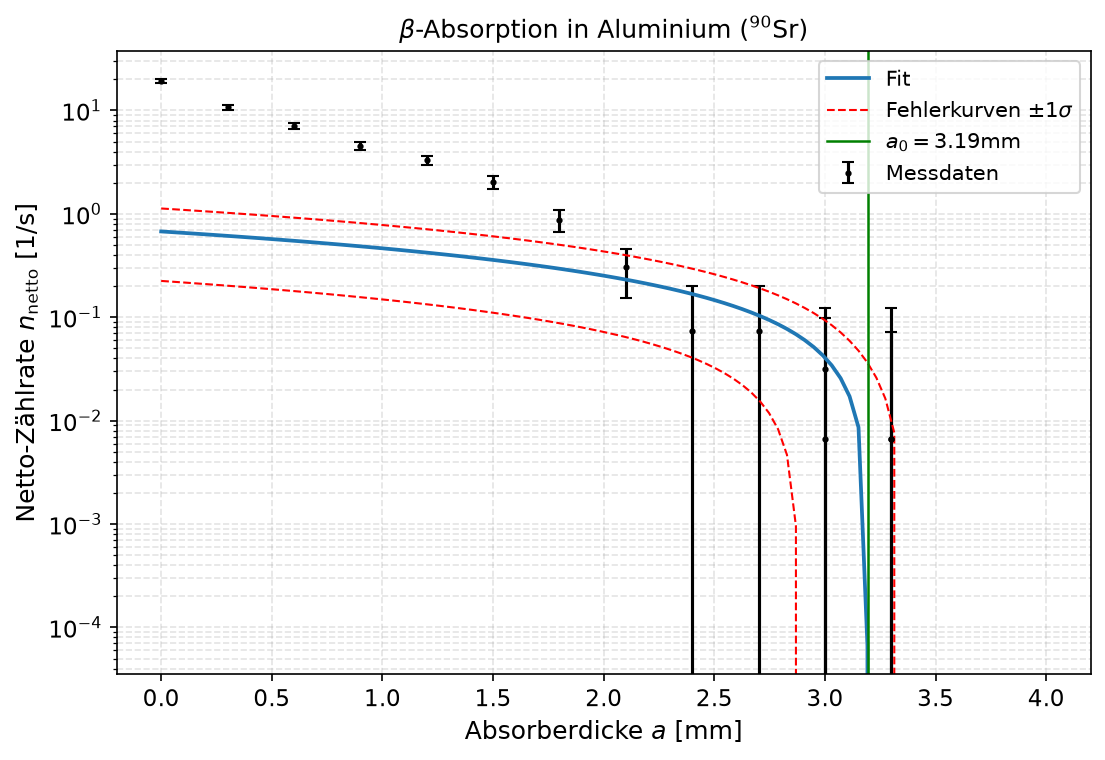

WindowsPath('figures/V253_Beta_Absorption.pdf')

In [ ]:
# ==========================================
# 2. BETA-ABSORPTION IN ALUMINIUM (Sr-90)
# ==========================================

# Im Folgenden wird die im Messprotokoll stets als Zählrate bezeichnete
#  Größe als Zerfallsrate n, bzw n_0^\beta verwendet; 
# diese ist nicht mit den im Messprotokoll als Klicks 
# beschriebenen Größe n zu verwechseln. Wir berechnen die
#  Zählraten erneut, um die ungerundeten Werte zu verwenden.

# Fehler rühren aus der statistischen Natur der radioaktiven 
# Zerfälle über die Poisson Verteilung; wir fügen n_err, etc. dynamisch als Spalte hinzu
from uncertainties import correlated_values
from scipy.optimize import root_scalar
# Daten laden
df_beta = io_utils.load_messdaten('data/raw/V253_Betastrahlung.csv')

# Zählraten und Fehler berechnen
df_beta['n'] = df_beta['N_counts'] / df_beta['t_s']
df_beta['n_err'] = np.sqrt(df_beta['N_counts']) / df_beta['t_s']

# n_0^\beta wird aus der letzten Zeile der csv Datei ausgelesen
n_0_beta_val = df_beta.iloc[-1]['n']
n_0_beta_err = df_beta.iloc[-1]['n_err']
n_0_beta = ufloat(n_0_beta_val, n_0_beta_err)

print(f"Spezifischer Beta-Nulleffekt n_0^beta = ({n_0_beta.n:.4f} ± {n_0_beta.s:.4f}) 1/s")

# Zählrate (bereinigt um Nulleffekt) und entsprechende Fehlerfortpflanzung
df_beta['n_netto'] = df_beta['n'] - n_0_beta.n
df_beta['n_netto_err'] = np.sqrt(df_beta['n_err']**2 + n_0_beta.s**2)

# Letzte Zeile (n_0^\beta) für den Fit und den Plot auslassen
df_fit = df_beta.iloc[:-1]
d_beta = df_fit['d_mm'].values
n_beta = df_fit['n'].values
n_beta_err = df_fit['n_err'].values
n_beta_netto = df_fit['n_netto'].values
n_beta_netto_err = df_fit['n_netto_err'].values

# Fit-Modell: linear m * x + c
# Nur die letzten fünf Messpunkte auswählen
d_fit = d_beta[-5:]
n_fit = n_beta_netto[-5:]
n_err_fit = n_beta_netto_err[-5:]

# Fit ausschließlich an diese fünf Punkte
# Fit gewichtet nach den Messfehlern (y_err=n_err_fit) ausführen.
# Gibt Parameter popt_b, Einzelfehler perr_b und Kovarianzmatrix pcov_b zurück
popt_b, perr_b, pcov_b = fitting.perform_fit(fitting.linear, d_fit, n_fit, y_err=n_err_fit)

# Erzeugt ufloats für m und c, welche die Nebendiagonal-Elemente
#  der Kovarianzmatrix Cov(m,c) beinhalten.
# Verhindert eine Überschätzung des Fehlers der Nullstelle
# (Da Fehler von m und c stark negativ korreliert sind, 
# vermutlich wegen der Auswahl von nur 5 Punkten?,
# können sie nicht als unabhängig betrachtet werden und wir 
# verwenden die Covarainzmatrix)
m_fit, c_fit = correlated_values(popt_b, pcov_b)

# Fitgerade und 1-Sigma-Fehlerkurven punktweise berechnen
x_fit = np.linspace(0, 4, 100)

# Fitgerade als ufloats für jeden X-Wert berechnen
y_fit_u = m_fit * x_fit + c_fit

# Mittelwert und Unsicherheit für jeden X-Punkt extrahieren
y_fit_val = np.array([y.n for y in y_fit_u])
y_fit_err = np.array([y.s for y in y_fit_u])

# Obere und untere Fehlerkurve definieren
y_fit_upper = y_fit_val + y_fit_err
y_fit_lower = y_fit_val - y_fit_err

# Nullstelle der aktuellen Fitgeraden = maximaler Absorberdicke
a_0_beta = -c_fit / m_fit

# Effektive Masse/Flächendichte
# Umrechnung von a_0 [mm] in [cm] durch (* 0.1), Multiplikation
#  mit Dichte Aluminium (rho = 2.6989 g/cm^3 
# (Quelle: Wikipedia (https://de.wikipedia.org/wiki/Aluminium)))
# und Addition der Korrektur für die Fenster-Flächendichte
#  des Zählrohrs (0.130 g/cm^2).
R_beta = 2.6989 * (a_0_beta * 0.1) + 0.130

# Chi2 berechnen und Ergebnisse ausgeben
chi2_data_b = stats.calculate_chi2(n_fit, fitting.linear(d_fit, *popt_b), n_err_fit, num_params=2)
stats.print_fit_results(popt_b, perr_b, ["m [1/(s*mm)]", "c [1/s]"], chi2_data_b)

# Rohwerte (.n) und ungerundete Unsicherheiten (.s) der berechneten Größen ausgeben
val_a0, err_a0 = a_0_beta.n, a_0_beta.s
val_Rb, err_Rb = R_beta.n, R_beta.s
print(f"Maximale Reichweite a_0: ({val_a0} ± {err_a0}) mm")
print(f"Flächendichte R_beta:   ({val_Rb} ± {err_Rb}) g/cm^2")

# Nullstellen der Hauptgeraden und der beiden Fehlerkurven bestimmen
# Haupt-Nullstelle (analytisch)
a_0_val = a_0_beta.n

# Funktionsdefinitionen für die punktweisen Fehlerkurven
f_upper = lambda x: (popt_b[0] * x + popt_b[1]) + np.sqrt(x**2 * pcov_b[0,0] + pcov_b[1,1] + 2*x*pcov_b[0,1])
f_lower = lambda x: (popt_b[0] * x + popt_b[1]) - np.sqrt(x**2 * pcov_b[0,0] + pcov_b[1,1] + 2*x*pcov_b[0,1])

# Numerische Berechnung der Schnittpunkte mit y = 0
a_0_lower = root_scalar(f_lower, bracket=[1.5, a_0_val]).root
a_0_upper = root_scalar(f_upper, bracket=[a_0_val, 3.8]).root

print(f"Grafische Schnittpunkte: a_0_lower = {a_0_lower:.2f} mm | a_0 = {a_0_val:.2f} mm | a_0_upper = {a_0_upper:.2f} mm")

# Fitgerade
x_fit = np.linspace(0, 4, 100)
y_fit = fitting.linear(x_fit, *popt_b)

# verrtikale Linie bei a_0
vlines =  [{'x': a_0_val, 'color': 'green', 'linestyle': '-', 'linewidth': 1.2, 'label': rf'$a_0 = {a_0_val:.2f}\mathrm{{mm}}$'}]

# Plot Beta-Absorption ( korrigierte Netto-Werte, 
# linearer fit, Fehlerkurven, vertikale Linien an Schnittpunkten mit x-Achse)
plotting.plot_with_fit(
    x=d_beta, y=n_beta_netto, y_err=n_beta_netto_err,
    x_fit=x_fit, y_fit=y_fit,
    y_fit_upper=y_fit_upper,
    y_fit_lower=y_fit_lower,
    vlines=vlines,
    xlabel=r'Absorberdicke $a$ [mm]', 
    ylabel=r'Netto-Zählrate $n_{\mathrm{netto}}$ [1/s]',
    title=r'$\beta$-Absorption in Aluminium ($^{90}\mathrm{Sr}$)',
    filename='V253_Beta_Absorption', 
    log_y=True
)


--- Fit-Ergebnisse ---
n_0_fit [1/s]: 8.6367e+00 ± 2.8694e-01
mu_Pb [1/cm]: 5.9883e-01 ± 2.2386e-02

Chi^2: 7.01
Red. Chi^2: 0.70
Freiheitsgrade: 10
Fitwahrscheinlichkeit: 72.40 %
Massenschwächungskoeffizient mu/rho: (0.0528 ± 0.0020) cm^2/g
Plot gespeichert unter: figures\V253_Gamma_Absorption.pdf


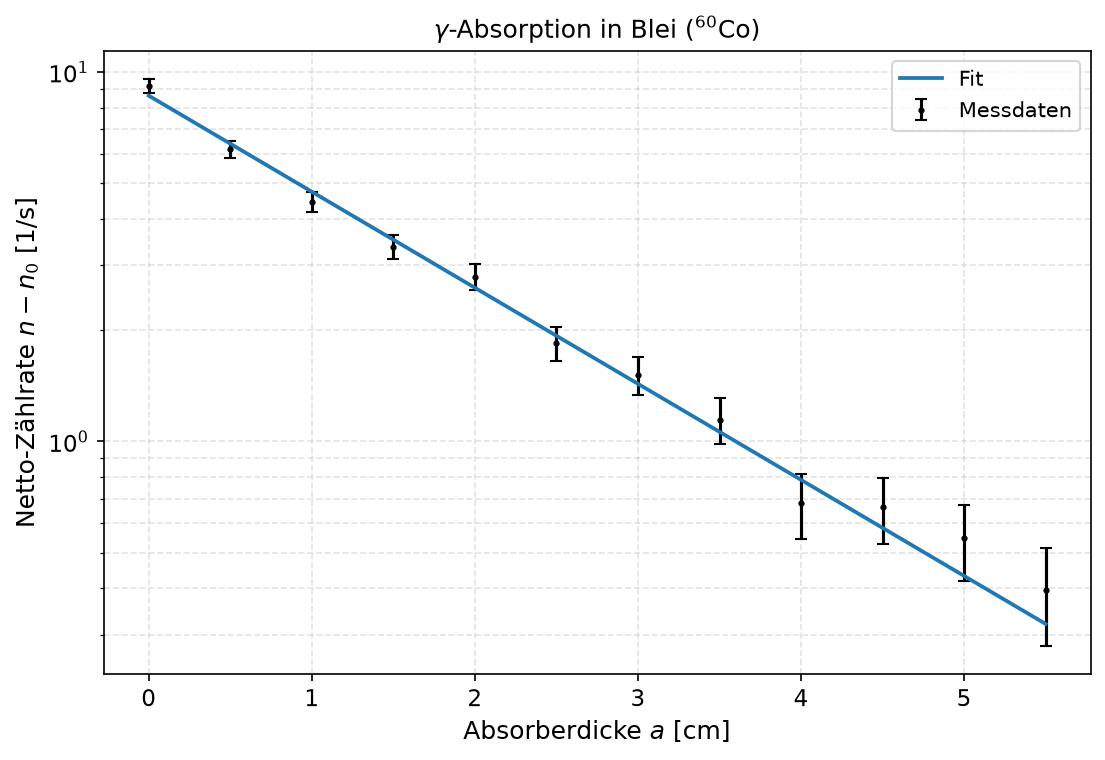

WindowsPath('figures/V253_Gamma_Absorption.pdf')

In [ ]:
# ==========================================
# 3. GAMMA-ABSORPTION IN BLEI (Co-60)
# ==========================================
df_gamma = io_utils.load_messdaten('data/raw/V253_Gammastrahlung_Absorption.csv')
n_0 = ufloat(106 / 300, np.sqrt(106) / 300)

df_gamma['n'] = df_gamma['N_counts'] / df_gamma['t_s']
df_gamma['n_err'] = np.sqrt(df_gamma['N_counts']) / df_gamma['t_s']
df_gamma['n_netto'] = df_gamma['n'] - n_0.n
df_gamma['n_netto_err'] = np.sqrt(df_gamma['n_err']**2 + n_0.s**2)

a_gamma = df_gamma['d_mm'].values / 10
n_g_netto = df_gamma['n_netto'].values
n_g_err = df_gamma['n_netto_err'].values

# Volle Kovarianzmatrix der Messdaten (Kovarianz aller 
# Punkte durch gemeinsamen Nulleffekt: Cov(y_i, y_j) = sigma_n0^2)
cov_y = np.full((len(n_g_netto), len(n_g_netto)), n_0.s**2)
np.fill_diagonal(cov_y, n_g_err**2)

# Lambert-Beer Fit: n_0 * exp(-mu * a)
def fit_lambert_beer(x, n0_fit, mu):
    return n0_fit * np.exp(-mu * x)

popt_g, perr_g, _ = fitting.perform_fit(fit_lambert_beer, a_gamma, n_g_netto, y_err=cov_y, p0=[10.0, 0.6])

mu_Pb = ufloat(popt_g[1], perr_g[1])
rho_Pb = 11.342 # g/cm^3 (Quelle: Wikipedia; https://de.wikipedia.org/wiki/Blei)
mass_mu_Pb = mu_Pb / rho_Pb

chi2_data_g = stats.calculate_chi2(n_g_netto, fit_lambert_beer(a_gamma, *popt_g), n_g_err, num_params=2)
stats.print_fit_results(popt_g, perr_g, ["n_0_fit [1/s]", "mu_Pb [1/cm]"], chi2_data_g)

val_mu, err_mu = unc.round_error_and_value(mass_mu_Pb.n, mass_mu_Pb.s)
print(f"Massenschwächungskoeffizient mu/rho: ({val_mu} ± {err_mu}) cm^2/g")

# Plot Gamma-Absorption
x_plot_g = np.linspace(0, a_gamma.max(), 100)
y_plot_g = fit_lambert_beer(x_plot_g, *popt_g)

plotting.plot_with_fit(
    x=a_gamma, y=n_g_netto, y_err=n_g_err,
    x_fit=x_plot_g, y_fit=y_plot_g,
    xlabel=r'Absorberdicke $a$ [cm]', ylabel=r'Netto-Zählrate $n - n_0$ [1/s]',
    title=r'$\gamma$-Absorption in Blei ($^{60}\mathrm{Co}$)',
    filename='V253_Gamma_Absorption', log_y=True
)

Halbwertsdruck p_1:       (415.79647103361594 ± 0.3097190951454282) mbar
Gesamtreichweite R_alpha: (3.874745488118364 ± 0.020558527185555724) cm
s_1: (1.62131891469179 ± 0.020558527185555724) cm
s_2: 1.5734265734265735 cm
Plot gespeichert unter: figures\V253_Alpha_Absorption.pdf


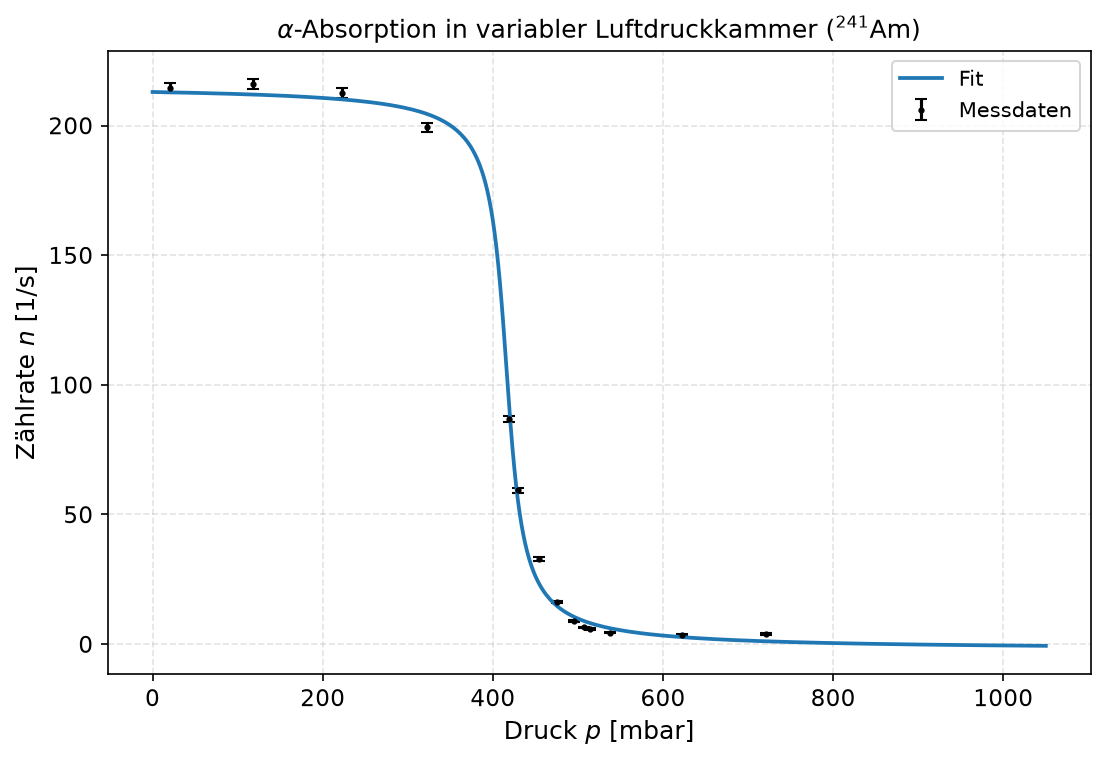

WindowsPath('figures/V253_Alpha_Absorption.pdf')

In [11]:
import uncertainties as unc
from uncertainties import ufloat
from uncertainties import unumpy as unp

# ==========================================
# 5. ALPHA-ABSORPTION IN LUFT (Am-241)
# ==========================================
df_alpha = io_utils.load_messdaten('data/raw/V253_Alphastrahlung.csv')

df_alpha['n'] = df_alpha['N_counts'] / df_alpha['t_s']
df_alpha['n_err'] = np.sqrt(df_alpha['N_counts']) / df_alpha['t_s']

p_alpha = df_alpha['p_mbar'].values
n_alpha = df_alpha['n'].values
n_alpha_err = df_alpha['n_err'].values

# Arctan-Fit
def fit_alpha_arctan(p, d, e, g, h):
    return d * np.arctan(e * p - g) + h

p0_alpha = [3000.0, 0.1, 35.0, 3000.0]
popt_a, perr_a, pcov_a = fitting.perform_fit(fit_alpha_arctan, p_alpha, n_alpha, y_err=n_alpha_err, p0=p0_alpha)


# Da die zweite Messung eine höhere Zählrate als die 
# ertse (bei geringerem Druck) ergab nutzen wir die 1ten 3 
# Messwerte (welche ca die gleiche Größenordnung 
# haben) um aus ihnen gemittelt die maximale Zählrate zu bestimmen.
# Maximale Zählrate aus den ersten 3 Messungen
n_max_val = np.mean(n_alpha[0:3])
n_max_err = np.sqrt(np.sum(n_alpha_err[0:3]**2)) / 3.0
n_half = ufloat(n_max_val / 2.0, n_max_err / 2.0)

# Fit-Parameter als ufloats inklusive Kovarianzen um 
# korrelation zwischen Parametern in Fehler mitzunehmen
d_u, e_u, g_u, h_u = unc.correlated_values(popt_a, pcov_a)

# Halbwertsdruck p_1 mit Fehlerfortpflanzung
p_1 = (unp.tan((n_half - h_u) / d_u) + g_u) / e_u

# Luftstreckenumrechnung (inklusive der 
# Korrekturfaktoren für Glimmer und Goldbeschichtung)
s_0 = ufloat(3.95, 0.05) # cm
p_0 = 1013.0             # mbar
s_1 = (p_1 / p_0) * s_0
s_2 = 2.25 / 1.43        # Glimmerfenster
s_3 = 0.68               # Goldschicht

R_alpha = s_1 + s_2 + s_3
#Berehchnung Fehler Gesamtreichweite
val_p1, err_p1 = (p_1.n, p_1.s) 
val_Ra, err_Ra = (R_alpha.n, R_alpha.s)
val_s1, err_s1 = (s_1.n, s_1.s) 
print(f"Halbwertsdruck p_1:       ({val_p1} ± {err_p1}) mbar")
print(f"Gesamtreichweite R_alpha: ({val_Ra} ± {err_Ra}) cm")
print(f"s_1: ({val_s1} ± {err_s1}) cm")
print("s_2:", (s_2), "cm")
# Plot Alpha-Absorption
p_plot_a = np.linspace(0, 1050, 500)
y_plot_a = fit_alpha_arctan(p_plot_a, *popt_a)

plotting.plot_with_fit(
    x=p_alpha, y=n_alpha, y_err=n_alpha_err,
    x_fit=p_plot_a, y_fit=y_plot_a,
    xlabel=r'Druck $p$ [mbar]', ylabel=r'Zählrate $n$ [1/s]',
    title=r'$\alpha$-Absorption in variabler Luftdruckkammer ($^{241}\mathrm{Am}$)',
    filename='V253_Alpha_Absorption'
)